# Setup

In [ ]:
!git clone https://github.com/ronalabrcns/DuckSeg

Cloning into 'DuckSeg'...
remote: Enumerating objects: 236, done.
remote: Counting objects: 100% (193/193), done.
remote: Compressing objects: 100% (132/132), done.
remote: Total 236 (delta 99), reused 127 (delta 52), pack-reused 43 (from 3)
Receiving objects: 100% (236/236), 119.27 MiB | 33.88 MiB/s, done.
Resolving deltas: 100% (105/105), done.
Updating files: 100% (37/37), done.


In [ ]:
!pip install git+https://github.com/vanvalenlab/cellSAM.git@362a8e521bcd7313d5cb280bcd4cfc12977c1e9f
!pip install nd2

  Cloning https://github.com/vanvalenlab/cellSAM.git (to revision 362a8e521bcd7313d5cb280bcd4cfc12977c1e9f) to /tmp/pip-req-build-f125v3h2
  Running command git clone --filter=blob:none --quiet https://github.com/vanvalenlab/cellSAM.git /tmp/pip-req-build-f125v3h2
  Running command git rev-parse -q --verify 'sha^362a8e521bcd7313d5cb280bcd4cfc12977c1e9f'
  Running command git fetch -q https://github.com/vanvalenlab/cellSAM.git 362a8e521bcd7313d5cb280bcd4cfc12977c1e9f
  Resolved https://github.com/vanvalenlab/cellSAM.git to commit 362a8e521bcd7313d5cb280bcd4cfc12977c1e9f
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-install-bo6uhe2h/segment-anything_fe1560de174a4a288c16a27e5a0daf07
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-install-bo6uhe2h/segme

In [ ]:
!pip install ipympl --quiet
get_ipython().kernel.do_shutdown(restart=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.0/519.0 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 117.0 MB/s eta 0:00:00


{'status': 'ok', 'restart': True}

> Wait until session reconnects!

In [ ]:
import sys
import os
sys.path.insert(0, os.path.abspath('./DuckSeg/src'))

In [ ]:
import numpy as np
import torch
from scipy.ndimage import binary_dilation
import matplotlib.pyplot as plt
import cv2

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device type {device.type}")

Device type cuda


In [ ]:
from google.colab import userdata

# Fetch from Colab Secrets and set as a system environment variable
os.environ['DEEPCELL_ACCESS_TOKEN'] = userdata.get('DEEPCELL_ACCESS_TOKEN')

# Loading experiment data

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
# Modify these to load experiment data from a directory
data_dir = "/content/drive/MyDrive/cell_segmentation/videos/MSH2/EV_siUTR"
name = "MSH2"

In [ ]:
from DuckSeg.experiment_loader import ExperimentBatch
batch = ExperimentBatch(name, data_dir)
print(f"Number of experiments in batch: {len(batch.experiments())}")

Number of experiments in batch: 4


## Calculate minumum number of frames for the experiments in the batch

In [ ]:
lens = []
for experiment in batch.experiments():
    lens.append(len(experiment.frames_u8()))
min_len = min(lens)
max_len = max(lens)
batch.max_len = min_len
print(f"Minimum number of frames {min_len}")
print(f"Maximum number of frames {max_len}")

Minimum number of frames 122
Maximum number of frames 242


# ROI Editor

Interactive editor for correcting ROI boundaries. Drag the black lines up/down to adjust ranges; changes are saved automatically next to the original ROI file.

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

%matplotlib widget
from DuckSeg.roi_editor import show_roi_editors
show_roi_editors(batch.experiments())

# Generating cell masks

## Config

In [ ]:
from DuckSeg.image_transformer import generate_masks_using_filters_and_transforms
from DuckSeg.image_transforms import convert_to_u8, threshold_image, adjust_contrast, set_brightness

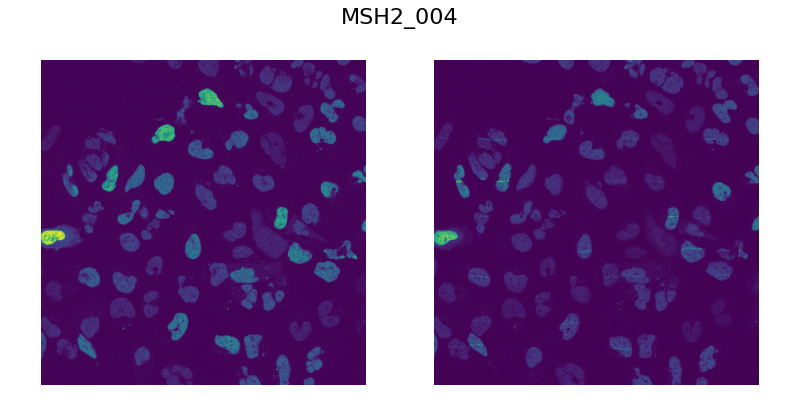

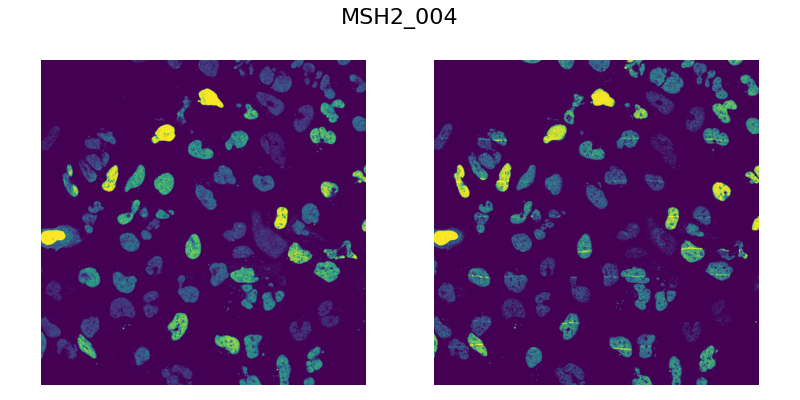

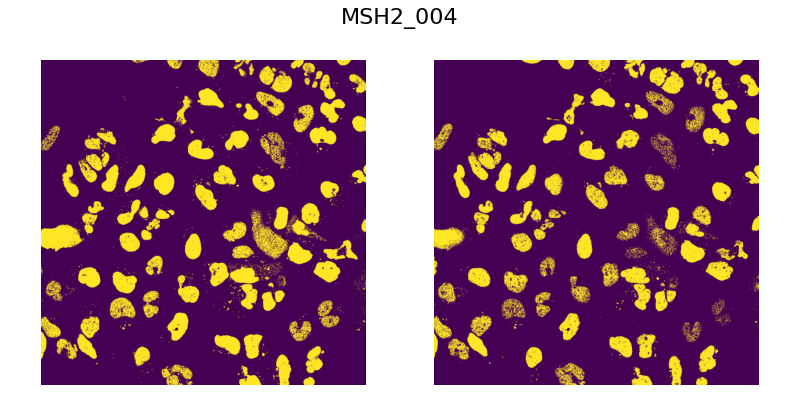

1.70GB [01:53, 16.1MB/s]


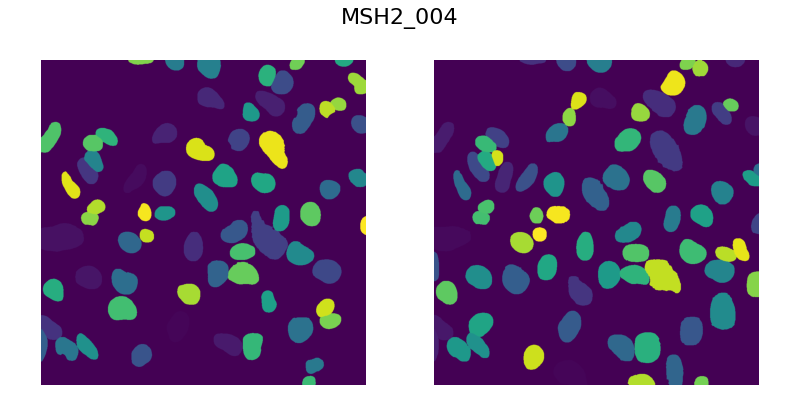

In [ ]:
# Filter which experiments from the batch are processed. This can speed up iteration time while tuning the filters
# Possible values:
#     None             all experiments
#     list of numbers  [0, 2, 4] only these experiments
#     string           all experiments containing the string. E.g. 'KO' will show all experiments whose file name includes 'KO'
experiment_filter = [0]
# Which frames to process from each experiment.
# Possible values:
#     integer           1, 2, 3, etc. Evenly split the experiment interval with N points.
#                       1 will show the first frame, 2 shows the first and last frames, 3 shows first, middle, last
#     list of integers  Show the frames specified in the list, e.g. [0, 10] shows the 0th and 10th frames
frame_filter = 2
# Additionally to the final result, show the processed frames after applying these tranforms. It must be a list of integers.
# Can be indexed with negative numbers to show the result after the last transform
show_after_transform = [0, 2,3]
# The list of transforms to perform on each image before handing it to the masking algorithm.
# You can find a list of transforms with examples in transforms.ipynb
transforms = [
    # Identity transform. With 0 in show_after_transform this will show the original images.
    lambda frame: frame,
    # Convert the data format into uint8. This must be done before genereating the masks. The masking algorithm cannot handle other formats
    convert_to_u8,
    set_brightness(20),
    threshold_image(20),
]

generate_masks_using_filters_and_transforms(batch, experiment_filter, frame_filter, transforms, show_after_transform)

# Cell video generation

This part applies the transforms to all experiments in the loaded batch and runs mask generation for each frame. This can take some time.

**Cache options**
- `use_cache = True`: reuse the saved result of a previous run for a video **only if its ROI lines are unchanged** (and `batch.max_len` is the same). If the ROI editor changed the lines of a video, the saved CellSAM segmentation is kept but the laser-hit cells are re-selected and re-tracked on the new lines.
- `save_cache = True`: save new or updated results to disk (in a `<video>_cache` folder next to each video).
- `reuse_segmentation = False`: when ROI lines changed, re-run CellSAM too instead of only re-tracking.
- The cache does not notice changes to `transforms`. After changing them, run once with `use_cache = False`.

In [ ]:
from DuckSeg.experiment_evaluator import evalute_batch

use_cache = True           # reuse saved results for videos whose ROI lines did not change
save_cache = True          # save new/updated results to disk
reuse_segmentation = True  # if only the ROI lines changed: keep the CellSAM masks, just re-track

vids = evalute_batch(batch, transforms=transforms, use_cache=use_cache, save_cache=save_cache, reuse_segmentation=reuse_segmentation)
print(f"{len(vids)} cell videos")

# Cell video outlier filtering

In [ ]:
# `vids` is already returned by evalute_batch above.
# Only needed if you skipped that cell: loads the saved results from disk (warns if a video's ROI changed since).
from DuckSeg.experiment_evaluator import ExperimentEvaluator

if 'vids' not in globals():
    vids = []
    for experiment in batch.experiments():
        print(f"Loading experiment {experiment.name}")
        exp = ExperimentEvaluator.load_experiment(experiment)
        vids += exp.cell_videos()


In [ ]:
from DuckSeg.cell_video_visualizer import normalize_videos_for_display

# Sets the size of the ROI range
range_modifier = 5
vids2 = normalize_videos_for_display(vids, range_modifier=range_modifier)

In [ ]:
import importlib
import DuckSeg.image_transforms

# Run this cell anytime you edit the image_transforms.py file to instantly update it!
importlib.reload(DuckSeg.image_transforms)

<module 'DuckSeg.image_transforms' from '/content/DuckSeg/src/DuckSeg/image_transforms.py'>

In [ ]:
# These set the checkboxes
manual_outliers = set()

In [ ]:
from DuckSeg.cell_video_visualizer import show_video_grid_jupyter
output.enable_custom_widget_manager()
batch_size = 30
updaters = []
for i in range(0, len(vids2), batch_size):
    updaters.append(show_video_grid_jupyter(vids2[i:i+batch_size], manual_outliers=manual_outliers))
update_outliers = lambda outliers, manual: [updater(outliers, manual) for updater in updaters]

In [ ]:
manual_outliers

{'',
 'MSH2_004_0',
 'MSH2_004_1',
 'MSH2_004_10',
 'MSH2_004_11',
 'MSH2_004_12',
 'MSH2_004_13',
 'MSH2_004_14',
 'MSH2_004_15',
 'MSH2_004_16',
 'MSH2_004_17',
 'MSH2_004_18',
 'MSH2_004_19',
 'MSH2_004_2',
 'MSH2_004_20',
 'MSH2_004_21',
 'MSH2_004_22',
 'MSH2_004_23',
 'MSH2_004_24',
 'MSH2_004_25',
 'MSH2_004_26',
 'MSH2_004_27',
 'MSH2_004_28',
 'MSH2_004_29',
 'MSH2_004_3',
 'MSH2_004_4',
 'MSH2_004_5',
 'MSH2_004_6',
 'MSH2_004_7',
 'MSH2_004_8',
 'MSH2_004_9'}

In [ ]:
from DuckSeg.outlier_filters import area_between, max_area_change_between_frames, max_total_area_change, id_starts_with
from DuckSeg.outlier_filters import outlier_vids

# copy the ids of cells here to always set them as outliers. For example {"REV7_WT_1700_001_24"}
extra_manual_outliers = {''}

filters = [
    area_between(10, 15000),
    #max_area_change_between_frames(2),
    #max_total_area_change(2),
    #id_starts_with('REV'),
]
outliers = outlier_vids(vids, extra_manual_outliers, filters)
_ = update_outliers(outliers, extra_manual_outliers)

In [ ]:
outliers

{''}

# Data evaluation and visualization

In [ ]:
cell_filter = lambda vid: vid.id not in outliers and vid.id not in manual_outliers

/content/DuckSeg/src/DuckSeg/experiment_evaluator.py:468: RuntimeWarning:

invalid value encountered in divide

/content/DuckSeg/src/DuckSeg/experiment_evaluator.py:678: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



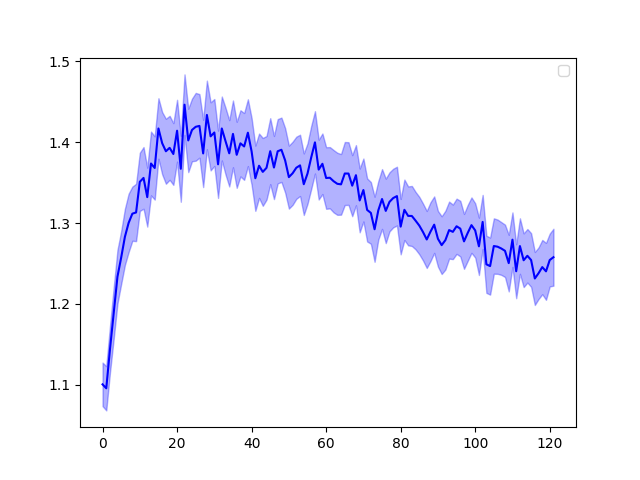

In [ ]:
import sys
import os
sys.path.insert(0, os.path.abspath('./DuckSeg/src'))

from DuckSeg.experiment_loader import ExperimentType
from DuckSeg.experiment_evaluator import ScoreType, plot_brightness_score_double, plot_brightness_score

plt.close('all')



_ = plot_brightness_score(
    batch,
    score_type=ScoreType.Ratio,
    range_modifier=range_modifier,
    cell_filter=cell_filter
)

In [ ]:
%mkdir output

mkdir: cannot create directory ‘output’: File exists


In [ ]:
from DuckSeg.video_exporter import export_cell_videos
export_cell_videos(vids, os.path.join("./output/", "brightness_scores.csv"), range_modifier=range_modifier)

In [ ]:
from DuckSeg.experiment_evaluator import plot_all_vid_scores
from DuckSeg.experiment_evaluator import calculate_brightness_score_for_videos, ExperimentType, ScoreType
ids, scores = calculate_brightness_score_for_videos(vids, score_type=ScoreType.Diff, range_modifier=range_modifier, cell_filter=cell_filter)
plot_all_vid_scores(scores, ids)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')